# Does the stand-in ratio tell a behaviour the model already performs from a new one?

*E53, performed anchor, 2026-10-29. Report: `reports/analyses/2026-10-29_analysis_e53-performed-anchor.md`.
Independently checked 2026-10-29: supported with corrections, applied here. Amendment 1b, a cipher twice
as broad, and Amendment 2, which settles kind against breadth from saved states, are the last two parts, 2026-10-30.*

## The answer

The stand-in ratio separates lowercase from the word swap by a wide margin. Lowercase read about 0.92 and the swap
about 0.26 on both seeds. Lowercase was also the broader update, so kind and breadth were confounded here. Amendment 2
settled that with a second pair, a half-known key table and a cipher on the same keys. There the half-known table was
about twice as targeted, yet still read high and the cipher low. So breadth does not explain the separation, though
on this pair alone it stays confounded. The relay did not separate the pair, and the null meant to test kind against
task failed.

## What we were trying to test

The line asks whether VPD can tell a fine-tune that draws out a behaviour the model already has from one that builds
something new. One number has told the two apart so far, but only on toy tables the original model performs neither of.
This run reads it on a pair whose labels the original model's own behaviour sets.

**The pair.** The 67M model and its frozen VPD decomposition. Two fine-tunes of the same 2,400 Pile rows, same recipe,
two batch orders each, which we call seeds:
- *Lowercase*, the performed member: the rows lowercased. Before any training, a check showed the original model
  already prefers the lowercase form of the next word on lowercased text, by about one nat.
- *Cipher*, the new member: the rows with fifty common words each swapped for another, everywhere. The original model
  prefers the unswapped word by about five and a half nats.

Each is read at up to 500 held-out positions where its behaviour shows. For lowercase, that is where the next word's
case changed; for the cipher, where the next token is a swapped word. Every number is the log-odds of the true next token there.

**The number.** Each update δW is given the least-squares split: the least-norm change $(dU, dV)$ to the
subcomponents with $dU V^\top + U dV^\top \approx \delta W$, the rest going to Δ. The stand-in model rebuilds the model
from the subcomponents alone, each multiplied by Γ's mask. Then:
- the *subcomponent gain* is how much the answer rises when the original subcomponents are swapped for the split ones,
  every mask open;
- the *masked gain* is the same rise with Γ's masks applied, the original model's masks before and the fine-tuned
  model's after;
- the *gate gain* is the part of it that Γ's new masks alone give the original subcomponents;
- the *stand-in ratio* is masked gain over subcomponent gain. It is roughly the gate gain over the subcomponent gain.
  It is not the share Γ keeps, and it has no ceiling at 1.

**The relay** is read in the real fine-tuned model, the update left in Δ. Every subcomponent is made to read the input
it would have had in the original model, at the scored position. The relay is the share of the gain this takes back:
1 means all of it passed through the original weights, 0 means the update's own write carried it.

**Controls and nulls.** A zero update, the update left in Δ, and the split's agreement with it had to read zero. A code
review found all three pass by construction, so they carry no information. A random update of the fine-tune's
off-target size, which learns nothing, sets each task's gain floor. A hand-made write into one matrix was meant to raise
the same answers while building nothing. It was meant to rule out that any update raising these answers reads like its
task. The
cipher was also saved at steps 10 and 100, to compare at a gain close to lowercase's.

## What we expected, and why

The original model already writes lowercase, so a lowercase fine-tune should mostly switch on subcomponents it already
has, and its ratio was leaned at 0.7 or above. The cipher pairs words the model never pairs, so it was leaned at 0.5 or
below, like the toy random maps. The scored rule takes the worst pair across seeds and asks for a gap of 0.3. The risk
was that any small broad update reads about 0.8. The relay was leaned not to separate, since on the toys both kinds
relayed about 0.7. The hand write, if it read within 0.15 of its task's fine-tune, would mean the ratio follows the
task.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "performed_anchor"
R = json.loads((EXP / "results" / "read.json").read_text())
ROWS, S = R["rows"], R["score"]
# figures: experiments/performed_anchor/plot.py, from read.json only
controls = [k for k, r in ROWS.items() if r["role"] == "control"]
print("read-stage controls passed:", all(ROWS[k]["ok"] for k in controls), "| P1:", S["P1"]["class"],
      "| P2:", S["P2_reported"]["class"], "| P3:", S["P3"]["verdict"])

read-stage controls passed: True | P1: separates | P2: does not separate | P3: unread


## Does the stand-in ratio read the performed task above the new one?

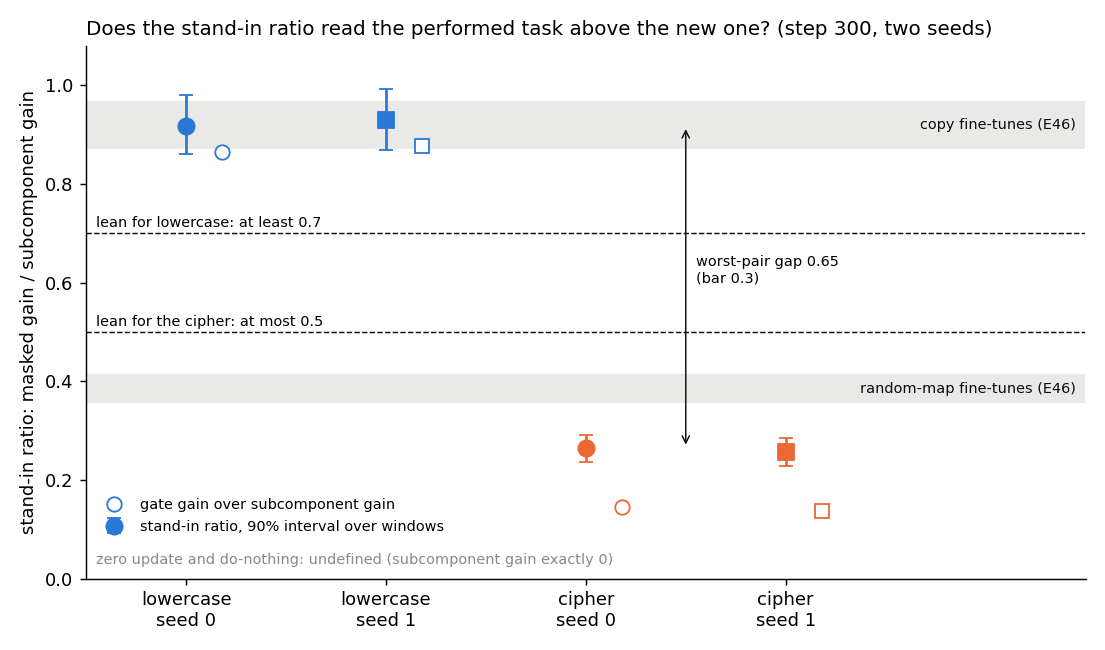

In [2]:
display(Image(filename=str(EXP / "figures" / "ratio.png")))

**Reading it.** Yes, by a wide margin. The two lowercase fine-tunes, blue, read 0.92 and 0.93, inside the
band of the toy copy fine-tunes. The two cipher fine-tunes, orange, read 0.26, below the band of the toy random maps.
The worst-pair gap is 0.65, more than twice the bar of 0.3. The intervals over windows are a few hundredths wide, and
the seeds agree within about a hundredth. The hollow markers, gate gain over subcomponent gain, separate the tasks too.
On the cipher they sit about 0.12 under the ratio. There the split's own changes add more than on any toy row, where
they added at most 0.05. That last reading is provisional.

In [3]:
rows = ["| fine-tune | gain G, nats | stand-in ratio | gate gain over subcomponent gain | relay |", "|---|---|---|---|---|"]
for task in ("lowercase", "cipher"):
    for s in (0, 1):
        r = ROWS[f"{task}/s{s}/step300"]
        rows.append(f"| {task}, seed {s} | {r['G']:.2f} | {r['masked_gain'] / r['piece_gain']:.3f} | "
                    f"{r['g'] / r['piece_gain']:.3f} | {r['relay']['rho']:.3f} |")
display(Markdown("\n".join(rows)))

| fine-tune | gain G, nats | stand-in ratio | gate gain over subcomponent gain | relay |
|---|---|---|---|---|
| lowercase, seed 0 | 1.67 | 0.919 | 0.866 | 0.657 |
| lowercase, seed 1 | 1.61 | 0.929 | 0.876 | 0.655 |
| cipher, seed 0 | 3.87 | 0.264 | 0.146 | 0.418 |
| cipher, seed 1 | 3.81 | 0.257 | 0.136 | 0.414 |

## Is the cipher's low ratio only a matter of gain size?

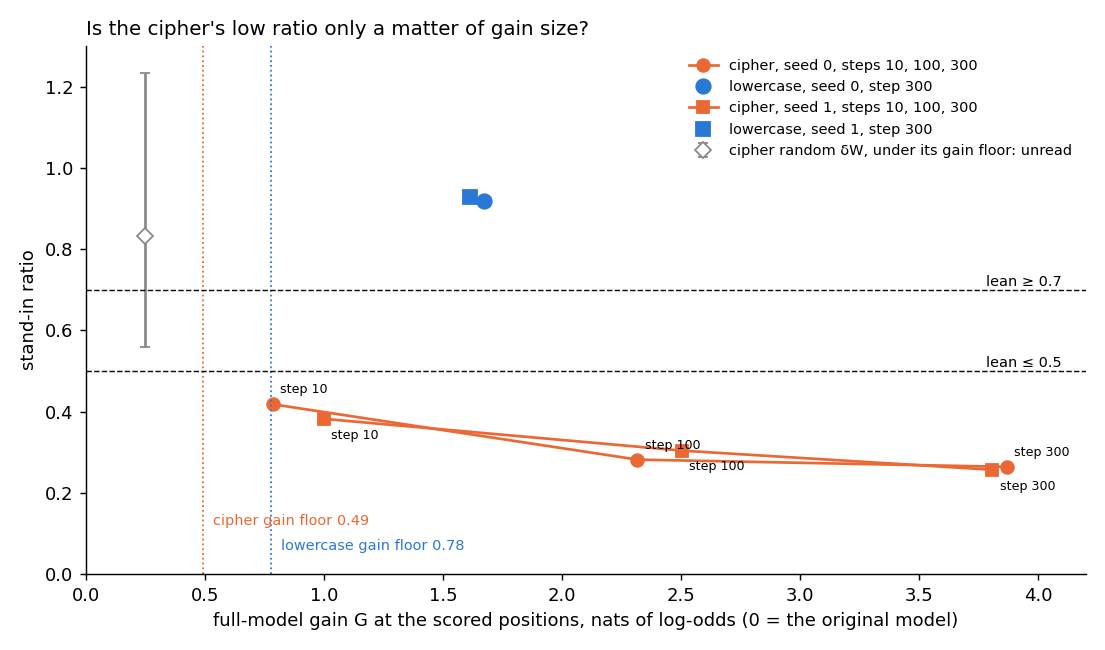

In [4]:
display(Image(filename=str(EXP / "figures" / "gain.png")))

**Reading it.** Not on the states we have. The cipher reads low at every gain saved, including the two that
bracket lowercase's. As its gain grew from under 1 nat to nearly 4, its ratio fell from about 0.4 to 0.26 on both
seeds. No cipher state matches lowercase's gain. The nearest saved states read 0.28 and 0.38, more than half a unit
below lowercase; that comparison is reported, not scored. A straight line between steps 10 and 100 gives about 0.35 at
lowercase's gain on both seeds, a provisional reading since the trend rises toward small gains. The grey diamond is the
cipher's random update. Its gain floor is twice its own gain, so it is unread by rule and plotted only for the range.

## Did the nulls land where the plan needed them?

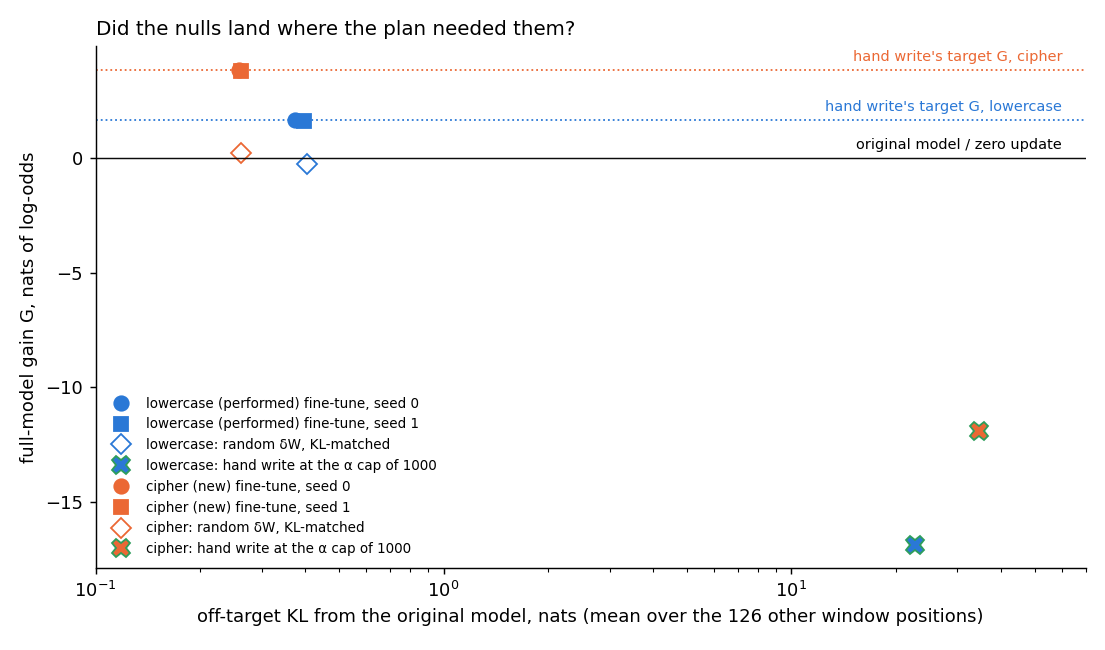

In [5]:
display(Image(filename=str(EXP / "figures" / "nulls.png")))

**Reading it.** The random updates landed; the hand writes failed. Each random update matched its fine-tune's
off-target size and moved the answer by a quarter of a nat or less, as planned. The hand writes were to match each fine-tune's
gain. Instead the scale search reached its cap without getting there. At the cap they pushed the answers down by 12 to
17 nats and moved the rest of the output sixty to a hundred and thirty times more than the fine-tunes did. On single windows the
write barely pointed at the answer. A plausible reason is that the input it reads does not tell which word comes next.
So the check that the ratio follows the kind of update, not the task, did not run. That is the main open caveat of
this result.

## Does the relay read the performed task above the new one?

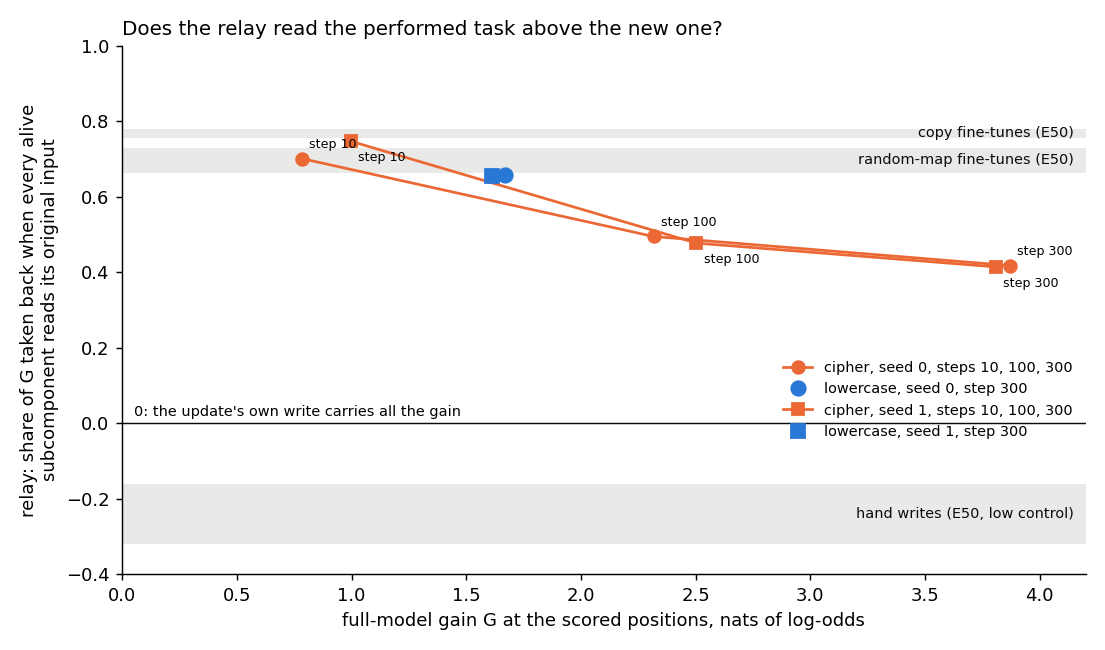

In [6]:
display(Image(filename=str(EXP / "figures" / "relay.png")))

**Reading it.** No, as expected. At step 300 lowercase relayed 0.66 of its gain and the cipher 0.42, a gap of
0.24 against the 0.3 bar. The cipher's relay also fell with training, from about 0.7 at step 10. Interpolated as for
the ratio, it reads about 0.6 at lowercase's gain, close to lowercase; that is provisional. So the relay may move with
gain size, but this run cannot say it does not move with kind. The cipher read below its leaned range of 0.6 to 0.8.

## Is it the kind of update, or its breadth?

A simpler explanation fits every row: lowercase is the broader update. About twice as many held-out positions qualify
for it, 4,598 against 2,198 for the cipher. The table divides each gain by the off-target KL, the full model's KL to
the original model on the other window positions. A high value means a targeted update, a low one a broad update.

| row | gain per off-target KL | gate gain per off-target KL | subcomponent gain per off-target KL | stand-in ratio |
|---|---|---|---|---|
| lowercase, step 300 | 4.1 to 4.5 | 3.1 to 3.4 | 3.6 to 3.9 | 0.92 to 0.93 |
| cipher, step 10 | 11.0 to 11.7 | 3.1 | 8.6 to 9.3 | 0.38 to 0.42 |
| cipher, step 100 | 14.2 to 14.8 | 2.1 to 2.5 | 11.8 to 12.3 | 0.28 to 0.30 |
| cipher, step 300 | 14.5 to 15.0 | 1.7 to 1.9 | 12.4 to 12.8 | 0.26 |

**Reading it.** Breadth and kind are fully confounded here. Every row orders the same on gain per off-target KL as on
its task. Where both are small, the gate gain per off-target KL is about equal on the two tasks. The difference sits in
the subcomponent gain per off-target KL, two to three times higher on the cipher. Since the ratio is roughly gate gain
over subcomponent gain, a targeted update could read low for that reason alone, whatever its kind. A working hand write
would not have settled this: it writes into one matrix on both tasks. So the run supports "the ratio separates these
two tasks", not yet "it separates a performed behaviour from a new one". This reading is not filed.

## Update size (provisional)

Each saved update's 24 matrices were measured on CPU: the Frobenius norm, and the stable rank, the squared Frobenius
norm over the squared largest singular value. Stable rank counts effective directions: 1 for a rank-one update.

| state | summed norm | mean stable rank | stand-in ratio |
|---|---|---|---|
| lowercase, step 300 | 11.6 to 11.8 | 28.5 to 28.6 | 0.92 to 0.93 |
| cipher, step 10 | 2.7 | 18.6 to 19.0 | 0.38 to 0.42 |
| cipher, step 100 | 7.3 to 7.4 | 28.5 to 29.0 | 0.28 to 0.30 |
| cipher, step 300 | 11.9 | 37.0 to 37.8 | 0.26 |

**Reading it.** Neither orders like the ratio. At step 300 the two tasks' updates are the same size yet read 0.92
against 0.26. Lowercase has the stable rank of the cipher at step 100, which reads 0.28 to 0.30. Weight-space size and
rank do not explain the separation; breadth in the output is not ruled out by this. Not filed.

## The method's limit

VPD's smallest unit is one subcomponent, not a circuit. A new mechanism built from subcomponents the original model
already has, under new masks, reads as "elicited" to every number here. The cipher's answers are common words whose
output subcomponents already exist, so it could have read high for that reason alone; it read low. A high reading means
"uses pieces the original model has", never "uses a circuit it already runs". Only a second decomposition seed narrows
this.

## What we learned

`GOALS.md` asks whether an update teaches something new or strengthens what exists. The stand-in ratio separated
lowercase from a 50-word cipher by a wide margin on both seeds, with labels the model's own behaviour sets. It does not
yet show that VPD tells elicitation from a new mechanism. Lowercase is also the broader update on every row, so a ratio
that read breadth would give the same result. The null that would rule out a task effect broke, and earlier hand writes
read near their fine-tunes, which tilts toward a task effect. The kind question is more open than one broken null
suggests. The real-model relay does not separate the pair.

## How compelling is the evidence

One task pair, one model, one decomposition, two batch orders per task. The gap is about ten times the widest
interval's half-width and five times its full width. Those intervals are a little too narrow, since windows from one
row share context. The ratio is read in Γ's stand-in model, not the real one. It is blind to whether an update that
builds nothing reads like its task, and to kind against breadth. Only four checks could fail in this run: the recipe,
the bf16 copies, the original model's check before training and the random update's size match. Nothing in the read
stage could fail. The ratio has no positive control in this run, and the relay no working low control. Neither
fine-tune makes its answer likely: both tasks are only partly learned.

## Surprises

- The hand writes failed outright: at no grid scale up to the cap did they reach their target, and at the cap they
  lowered the answers by 12 to 17 nats.
- The intervals over windows were three to six times wider than the filed expectation of about a hundredth.
- The cipher's relay fell with training to 0.42, below its leaned range.
- On the cipher, the split's changes add about 0.12 of the subcomponent gain beyond the gate gain. On the toys it was
  at most 0.05. Provisional.

## What next

1. **A pair matched in breadth.** If a performed task as targeted as the cipher reads high, the ratio follows kind; if
   it reads low, breadth.
2. **A task-matched null that reaches its gain.** If it reads like its task, the ratio reads the task, not the kind.
3. **A second decomposition seed**, the one check that narrows the method's limit. Qwen waits for items 1 and 2.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| P1 | the ratio reads lowercase above the cipher | worst-pair gap ≥ 0.3 | 0.65 | separates |
| P2 | the relay reads lowercase above the cipher | the same, reported | 0.24 | does not separate, as leaned |
| P3 | a hand write reads like its task | within 0.15 | writes at the cap | unread |
| controls | zero update, do-nothing, same gain | within 0.001 | exactly 0 | pass, by construction |
| recipe | lowercase reproduces E37 | within 0.005 of 0.1301 | 0.1296 | pass |

Leans and the matched-gain rows: the report.

## Not run

- A working hand write or other task-matched null, so the task-or-kind question stays open.
- The hand writes' relay as a low control on these tasks.
- A pair matched in breadth; a positive control for the ratio within this run.
- A cipher state at exactly lowercase's gain; a second decomposition seed; another task pair; Qwen.

**Provenance.** MATS cluster L40, `debug` QoS, $0; fine-tune 107 s, read 217 s; run commit `f848100`. Results
`experiments/performed_anchor/results/read.json`; filed rules `results/predictions.json`.

# Amendment 1b: does a cipher twice as broad read higher?

*2026-10-30, jobs 45971 and 45972. Report: the "Amendment 1b" section of the same analysis file.*

## The answer

Not answered. The filed rule needed the new cipher to be at least as broad as lowercase, and it was not. It buys about
7.8 nats of gain per nat of change elsewhere, against lowercase's 4.5 to 4.9. It is twice as broad as the first cipher.
Its stand-in ratio sat 0.01 to 0.02 above the first cipher's at the end of training. At the step where the two
ciphers' gains match it sat about 0.07 above, a tenth of the gap to lowercase. So, provisionally, closing most of the
breadth gap left the ratio far below lowercase, at most about 0.07 above the first cipher.

## What we were trying to test

Lowercase read high and the cipher low, but lowercase is also the broader update. A planned swap, a narrow performed
task against a broad new one, lost its narrow member: the original model does not lowercase those words inside cased
text. So the user chose to run the broad new member alone.

**The broad cipher.** The same 2,400 Pile rows with 500 common words swapped instead of 50: ranks 50 to 549 in Pile
frequency. The swap touches 9% of training tokens, about four times the first cipher's share. The original model
prefers the unswapped word by 5 nats, so it cannot do the task. Same recipe, two seeds, saved at steps 10, 100 and 300.

**Breadth** is the full model's gain divided by the true off-target KL. That KL is the full model's KL to the original
model, averaged over window positions that do not predict one of the task's own tokens. High means targeted, low means
broad. The stand-in ratio is as above: roughly the gate gain over the subcomponent gain, not the share Γ keeps.

## What we expected, and why

First, the new cipher had to be at least as broad as lowercase on both seeds; otherwise the result is "not read". Then
both of its ratios at 0.5 or below would mean breadth does not explain the gap, and both at 0.7 or above that it does.
The lean was "does not explain", since every cipher-like update so far read between 0.26 and 0.42.

In [7]:
A = json.loads((EXP / "results" / "read_amend1b.json").read_text())
AR, AS = A["rows"], A["score"]
# figures: experiments/performed_anchor/plot_amend1b.py, from read_amend1b.json (and read.json for E53's cipher steps)
print("repro control:", all(AR[f"e53/{t}/s0/step300"]["ok"] for t in ("lowercase", "cipher")),
      "| breadth requirement met:", AS["gate"]["achieved"], "| outcome:", AS["outcome"])

repro control: True | breadth requirement met: False | outcome: not read (swap missed)


## Is the broad cipher at least as broad as lowercase?

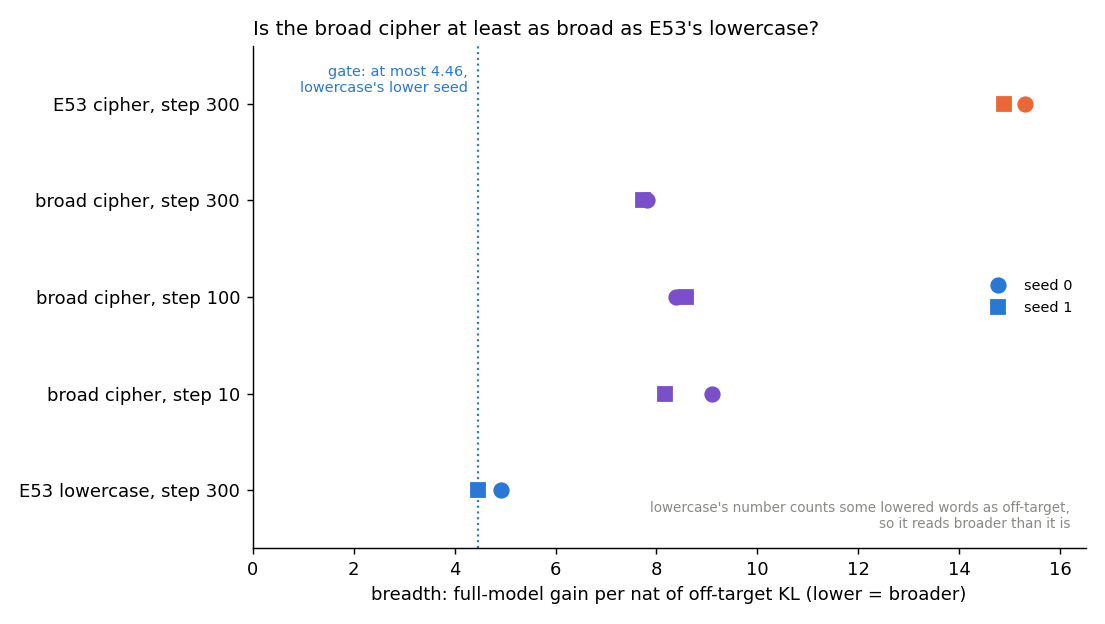

In [8]:
display(Image(filename=str(EXP / "figures" / "a1b_breadth.png")))

**Reading it.** No. At step 300 the broad cipher, purple, reads 7.7 to 7.8. Lowercase, blue, reads 4.5 to 4.9, and
the filed bar sat at its lower seed. So the outcome is "not read". The broad cipher is twice as broad as the first
cipher, orange, at about 15. It was most targeted at step 10 and broadened as it trained, so no saved step reaches
lowercase.

There is a caveat on the bar. Lowercase's task also changes positions it does not score: capitals with no space before
them, and words the tokenizer splits differently once lowercased. Their change counts as off-target, so lowercase reads
broader than it is, and the bar was harder to pass than intended. It was scored as filed. The same check confirms that
lowercase is broader than the first cipher on the true KL, threefold, so the confound from the first run is real.
Closing that gap would need about two-thirds of lowercase's off-target KL to come from the miscounted positions, which
is not measured.

## Does a cipher twice as broad read higher?

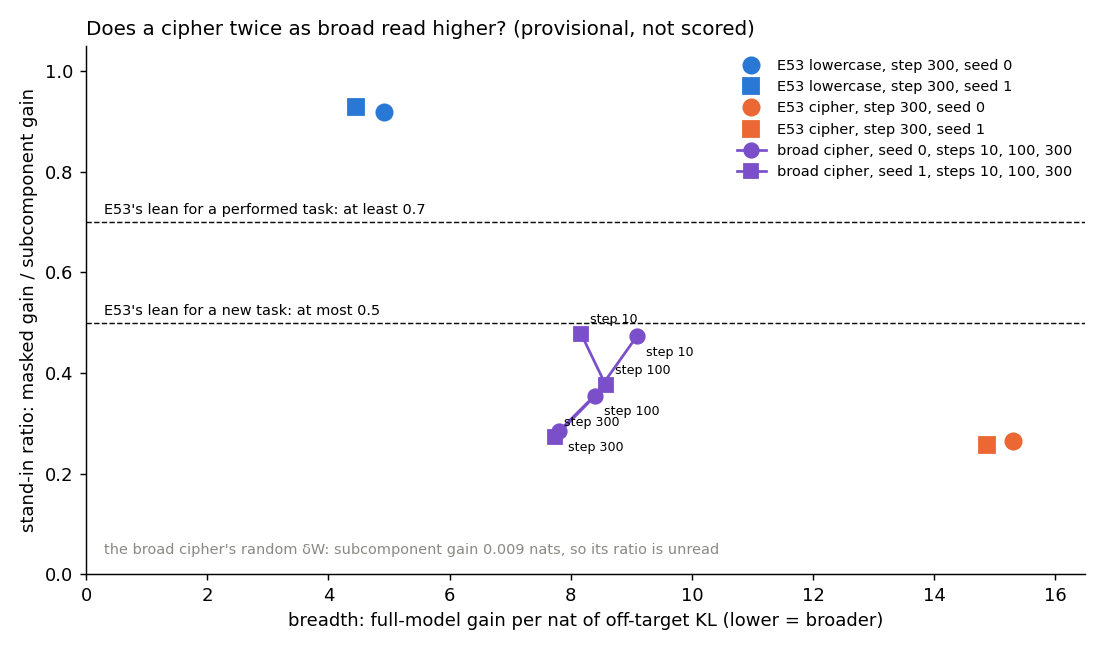

In [9]:
display(Image(filename=str(EXP / "figures" / "a1b_ratio.png")))

**Reading it.** Only a little, provisionally and unscored. At step 300 the broad cipher reads 0.27 and 0.29, against
the first cipher's 0.26, but the first cipher had more gain there and the ratio falls with gain. At step 100 the two
ciphers' gains match, and the broad cipher reads about 0.07 higher: 0.36 and 0.38 against 0.28 and 0.30. Lowercase
reads 0.92. A high ratio like lowercase's means only "uses pieces the original model has": a new circuit built from old pieces would also read as elicited. So a cipher most of the way to lowercase's breadth rose by a tenth of the gap at most.
This cannot rule out three things. A breadth effect could appear only nearer lowercase's breadth. The two ciphers
swap different words, so they are not one task at two breadths. And both low readings are word swaps, so task family
is still confounded with kind.

In [10]:
rows = ["| state, step 300 | gain G, nats | breadth | stand-in ratio | 90% interval |", "|---|---|---|---|---|"]
for name, key in (("E53 lowercase", "e53/lowercase"), ("broad cipher", "broad_cipher"), ("E53 cipher", "e53/cipher")):
    for s in (0, 1):
        r = AR[f"{key}/s{s}/step300"]
        lo, hi = r["boot"]["ratio_ci90"]
        rows.append(f"| {name}, seed {s} | {r['G']:.2f} | {r['G'] / r['kl_off']:.1f} | "
                    f"{r['masked_gain'] / r['piece_gain']:.3f} | {lo:.2f}-{hi:.2f} |")
display(Markdown("\n".join(rows)))

| state, step 300 | gain G, nats | breadth | stand-in ratio | 90% interval |
|---|---|---|---|---|
| E53 lowercase, seed 0 | 1.67 | 4.9 | 0.919 | 0.86-0.98 |
| E53 lowercase, seed 1 | 1.61 | 4.5 | 0.929 | 0.87-0.99 |
| broad cipher, seed 0 | 3.32 | 7.8 | 0.285 | 0.25-0.32 |
| broad cipher, seed 1 | 3.28 | 7.7 | 0.273 | 0.24-0.31 |
| E53 cipher, seed 0 | 3.87 | 15.3 | 0.264 | 0.24-0.29 |
| E53 cipher, seed 1 | 3.81 | 14.9 | 0.257 | 0.23-0.29 |

## At lowercase's gain, where does the broad cipher read?

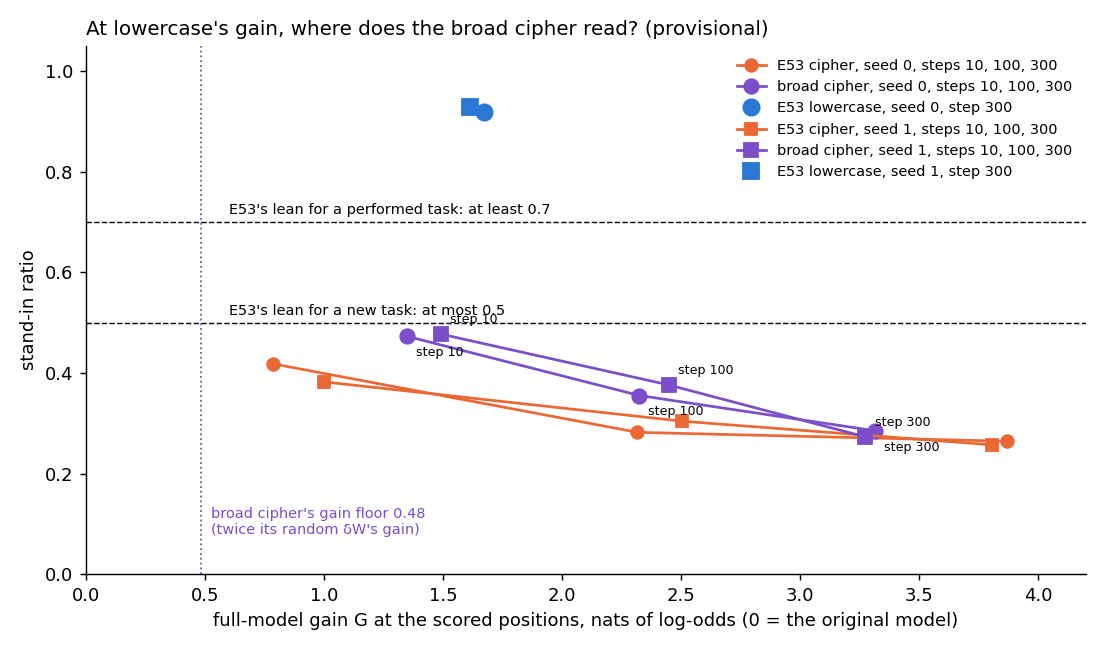

In [11]:
display(Image(filename=str(EXP / "figures" / "a1b_gain.png")))

**Reading it.** Still low, though higher than at the end of training; reported, not scored. The nearest saved
state is step 10 on both seeds, at a gain of 1.35 and 1.49 nats against lowercase's 1.6 to 1.7. There it reads 0.47
and 0.48, against lowercase's 0.92 and 0.93. Both ciphers' ratios fall as their gain grows. The broad one sits above
the first at every gain, by about 0.07 where their gains match. At step 10 the broad cipher is also at its most targeted, so this matches gain
but widens the breadth gap.

**The random update gives no reference.** It was matched to the fine-tune on the pooled KL, 0.436 against 0.448
nats, and gained 0.24 nats, which sets
the gain floor at 0.48. But its subcomponent gain was 0.009 nats, so its ratio divides by almost nothing. In 94% of
bootstrap resamples that gain fell under 0.1 nats; the interval of 1.1 to 2.3 comes from the rest. It says nothing
about what ratio an update that learns nothing would read.

## What we learned

Whether breadth alone explains the gap is not answered: no new update reached lowercase's breadth. Two things are
firmer. Lowercase is broader than the first cipher on the true off-target KL too, so the confound is real. And a cipher
twice as broad still read far below lowercase, at most about 0.07 above the first cipher at matched gain, a tenth of
the gap. Provisionally that tilts against "the ratio reads breadth" over this range.

## How compelling is the evidence

One new task at two seeds, one model, one decomposition. The intervals over windows are about ±0.035 at step 300, and
the seeds agree within about a hundredth. The repro control could fail and passed exactly. The ratio has no positive
control in this run and the random update gives it no low reference. Breadth is one definition, and lowercase's value
under it leans broad.

## Surprises

- The broad cipher grew broader as it trained; the first cipher grew more targeted, on the pooled KL.
- Otherwise none: the ratio stayed low as leaned, and the breadth requirement, leaned to pass, missed.

## What next

1. **Correct lowercase's breadth** by leaving every position the lowercasing changed out of its off-target KL. If it
   rises past 7.8, this run can be read under an amended rule.
2. **A broader new task**, a swap over many more words. If it stays near 0.3 at lowercase's breadth, breadth is ruled out.
3. **A performed task as targeted as the cipher**, to read kind directly.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| e53_repro | this code reproduces the first run | gain within 0.02, ratio within 0.01 | exact | pass |
| gate | the broad cipher is as broad as lowercase | its max breadth ≤ lowercase's min | 7.81, 7.74 vs 4.92, 4.46 | missed |
| outcome | breadth explains the gap or not | ratios ≤ 0.5 or ≥ 0.7 | gate missed | not read |
| e53 order | lowercase broader than the first cipher | true off-target KL | 4.5-4.9 vs 14.9-15.3 | lowercase broader, reported |
| matched gain | broad cipher at lowercase's gain | reported | 0.473, 0.477 at step 10 | below 0.5 |

## Not run

- The filed outcome, since the breadth requirement missed; a new update as broad as lowercase.
- A lowercase off-target KL that leaves out every position the lowercasing changed.
- A performed task as targeted as the cipher; a low reference or positive control for the ratio.
- The relay and hand write for the broad cipher; a second decomposition seed; Qwen.

**Provenance.** MATS cluster L40, `debug`, $0; fine-tune 46 s, read 134 s; jobs 45971 and 45972; results commit
`061067a`. Results `results/read_amend1b.json`; filed rules `results/predictions_amend1b.json`.

**Departures from the literature.** None: the ratio, breadth and the gain floor are this project's own definitions.

# Amendment 2: is the ratio's separation only a matter of breadth?

*2026-10-30, job 46174, no fine-tune. Report: the "Amendment 2" section of the same analysis file.*

## The answer

No: breadth does not explain the separation, by the filed reading. A second pair, from E54, is a key-to-word table the
original model already half-knows and a cipher on the same keys. The half-known table was about twice as targeted as the
cipher, yet its stand-in ratio read 0.95 against the cipher's 0.29 to 0.34. In the lowercase pair the high-ratio member
was the broader one. So the performed member reads high whichever side of its partner it sits on. Within the Pile
tasks alone the question stays open: corrected, lowercase is still broader than the 500-word cipher.

## What we were trying to test

Lowercase read high and the cipher low, but lowercase was also the broader update. The 500-word cipher did not reach its
breadth, and a review found lowercase's breadth biased toward broad. Two saved results could settle the question
without training anything new.

**Breadth** is the full model's gain at the scored positions divided by the true off-target KL. That KL is the mean KL
from the original model to the fine-tuned one, over window positions whose next token the task did not change. High
means targeted, low means broad. Values compare within a pair read on the same windows, not across pairs.

**Part one** corrects lowercase's count. Lowercasing also changes capitals with no space before them, words the
tokenizer splits differently once lowered, and padding. Those positions, 13 per window beside 10 scored ones, used to
count as off-target. Now every position whose next token the task changed is left out. For a token-for-token cipher
nothing moves, since its changed positions are its scored ones.

**Part two** places E54's pair on the breadth axis. Each E54 window is 41 tokens of Pile text, a rare marker, then a key
word; the model must predict the key's value. In the *elicit map* each value is a word the original model already ranks
2nd to 20th there, so it does this task weakly. In the *cipher* the same keys map to words it gives under 1e-4, so it
cannot. The two fine-tunes were read where their update sizes match, and their gains match too. Their stand-in ratios,
0.95 against 0.29 to 0.34, were computed by the plan writer from E54's saved cells before this amendment was filed: an
input, not a prediction. The ratio is roughly the gate gain over the subcomponent gain. It is not the share Γ keeps.

## What we expected, and why

The plan guessed the extra lowercase positions carry about 0.8 nats of KL each. That would raise lowercase to 5.4 to 6.0,
still short of the broad cipher's 7.8, so the first check was leaned to miss. E54's breadth was unmeasured; the three
outcomes were leaned about equally. The elicit map might be the broader update, since its word pairs also occur in plain
text.

In [12]:
B = json.loads((EXP / "results" / "read_amend2.json").read_text())
BR, BS = B["rows"], B["score"]
# figures: experiments/performed_anchor/plot_amend2.py, from read_amend2.json (and read_amend1b.json for E53's ratios)
print("stage-0 controls passed:", all(r["ok"] for r in BR.values() if r["role"] == "control"),
      "| lowercase vs broad cipher:", BS["P1"]["class"], "| E54 breadth order:", BS["P2"]["class"],
      f"(x = {BS['P2']['x']:.2f})", "| reading:", BS["reading"])

stage-0 controls passed: True | lowercase vs broad cipher: missed | E54 breadth order: reversed (x = 2.21) | reading: breadth does not explain the separation


Every stage-0 check passed, and each could have failed. This code reproduced E53's two seed-0 rows exactly and
E54's two seed-0 gains within 0.006. On both ciphers the corrected KL equalled the old one bit for bit. The read took 67
seconds on an L40, at $0.

## Corrected, is lowercase as targeted as the broad cipher?

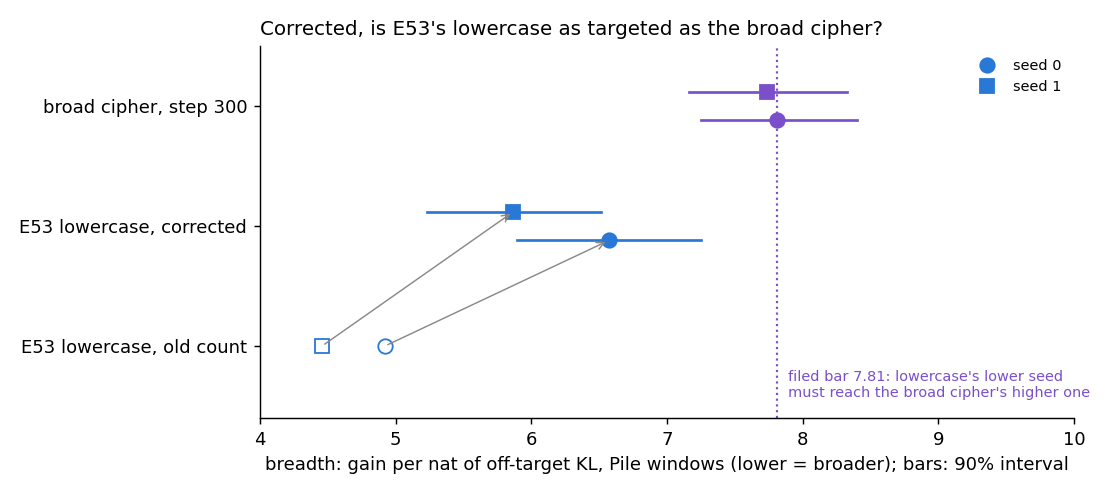

In [13]:
display(Image(filename=str(EXP / "figures" / "a2_breadth.png")))

**Reading it.** No, though the gap narrowed. The hollow markers are lowercase's old breadth, 4.9 and 4.5; the
arrows lead to the corrected values, 6.6 and 5.9. The broad cipher, purple, reads 7.8 and 7.7, so the filed check
missed, as leaned. Lowercase is now 1.2 to 1.3 times broader instead of 1.6 to 1.8. The changed positions carried
about 1.0 nats of KL each, a little more than guessed. So within the Pile tasks, no new update as broad as lowercase
has been read, and the lowercase pair alone still confounds kind with breadth.

## In the second pair, is the performed member the broader one?

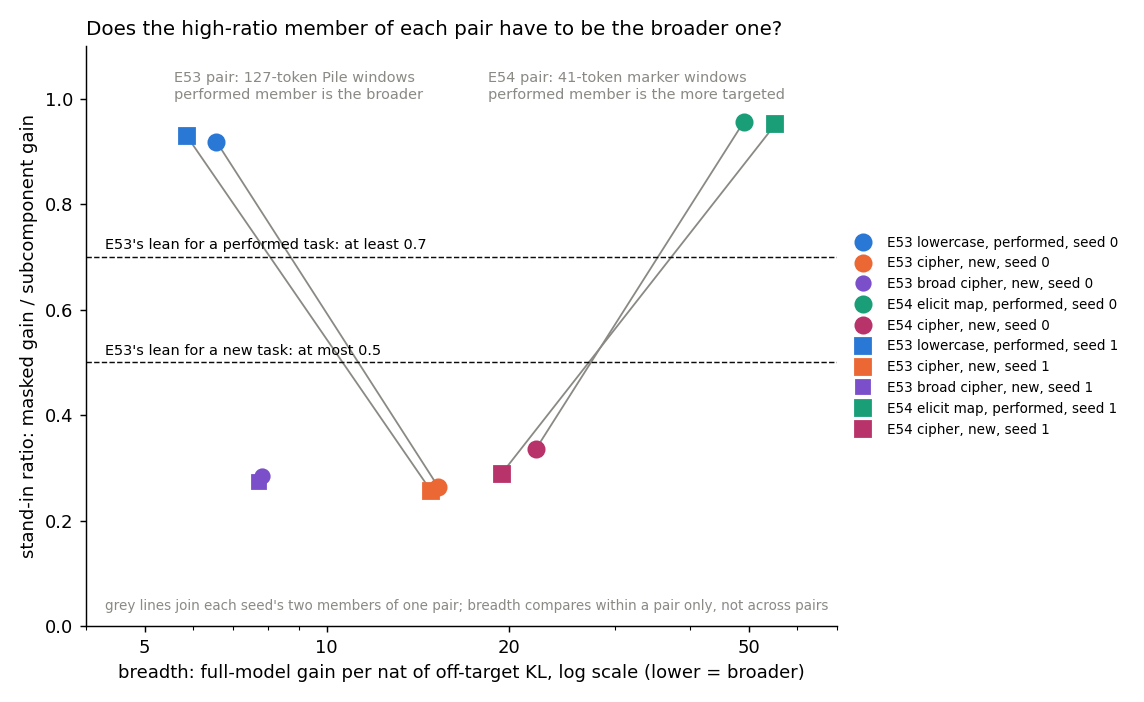

In [14]:
display(Image(filename=str(EXP / "figures" / "a2_ratio_breadth.png")))

**Reading it.** No, the reverse: the elicit map, green, is about twice as targeted as its cipher, red. It gains
49 and 55 nats per nat of off-target KL, the cipher 22 and 19.5. The gains match, so the difference sits in the KL
elsewhere: about 0.2 nats against 0.5. Yet the elicit map reads 0.95 and the cipher about 0.3. The grey lines join each
pair: the lowercase pair falls from its broad performed member to its targeted new one, while E54's rises from its
broad new member to its targeted performed one. The performed member reads high both times, so the filed reading is
"breadth does not explain the separation". The two pairs sit on different windows, so the shared axis shows each
pair's shape, not distances between pairs.

In [15]:
rows = ["| E54 state | gain, log-odds | off-target KL | breadth | stand-in ratio |", "|---|---|---|---|---|"]
for task, name in (("elicit", "elicit map"), ("cipher", "cipher")):
    for s in (0, 1):
        r = BR[f"e54/{task}_s{s}"]
        rows.append(f"| {name}, seed {s} | {r['G']:.2f} | {r['kl_off_changed']:.3f} | "
                    f"{BS['breadth'][f'e54/{task}_s{s}']:.1f} | {BS['e54_ratio_reported'][f'{task}_s{s}']:.3f} |")
display(Markdown("\n".join(rows)))

| E54 state | gain, log-odds | off-target KL | breadth | stand-in ratio |
|---|---|---|---|---|
| elicit map, seed 0 | 10.80 | 0.220 | 49.0 | 0.956 |
| elicit map, seed 1 | 10.82 | 0.196 | 55.3 | 0.951 |
| cipher, seed 0 | 11.10 | 0.500 | 22.2 | 0.336 |
| cipher, seed 1 | 10.88 | 0.559 | 19.5 | 0.289 |

## What we learned

The ratio's separation is not a reading of breadth: a performed update twice as targeted as its new partner still read
0.95 against about 0.3. Within the Pile tasks the confound remains, but a second family now orders the same way with
breadth reversed. For the adopted programme this closes its first step. The ratio goes to the second, a table of the
ratio and the re-gating share on states labelled by a definition of reuse that owes nothing to the decomposition.

## How compelling is the evidence

Two task families, each with a performed and a new member, two seeds each, one model and one decomposition. Breadth
intervals over windows are about ±10% and never touch across a pair's members; E54's twofold difference is about ten
times its seed spread. E54's ratios come from its own implementation of the same cells, read once, with no interval.
A high ratio means only "uses pieces the original model has": a new circuit built from old pieces would also read as
elicited. And E54's "performed" is weak: the original model gives each value a small probability, not its first guess.

## Surprises

- E54's pair had been described as matched in breadth by construction. It is not: the half-known table is twice as
  targeted. That outcome was one of three leaned about equally, so it is a finding, not a failed prediction.
- The changed lowercase positions carried about 1.0 nats each, not 0.8; seed 0 landed just above its expected band.

## What next

1. **The programme's second step**: the ratio and the re-gating share on E55's labelled states. If the ratio disagrees
   with those labels on lowercase or copy, it is not a reading of reuse.
2. **E54's states through this experiment's code**, with intervals, minutes at $0. If the ratios move beyond their
   intervals, the second half of this reading needs revisiting.
3. A broader Pile cipher is no longer called for; it matters only if one task family must carry the argument alone.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| controls | reproductions and the identity on ciphers | filed tolerances | exact or within 0.006 | pass |
| P1 | corrected lowercase as targeted as the broad cipher | min lowercase ≥ max broad cipher | 6.57, 5.87 vs 7.81, 7.74 | missed, as leaned |
| P2 | E54's breadth order | x = min elicit / max cipher | 2.21 | reversed |
| reading | does breadth explain the separation | P2 reversed or matched | reversed | breadth does not explain it |
| E54 ratios | input from E54's cells, not filed | reported | 0.956, 0.951, 0.336, 0.289 | performed high, new low |

## Not run

- The ladder of broader Pile ciphers; the reading did not call for it.
- E54's states through this experiment's split code, and intervals on E54's ratios.
- An off-target KL that also leaves out the changed context after a changed token.
- A performed Pile task as targeted as the cipher; a second decomposition seed; Qwen.

**Provenance.** MATS cluster L40, `debug`, $0; 67 s; job 46174 at commit `e4b7965`; results commit `5c311dd`. Results
`results/read_amend2.json`; filed rules `results/predictions_amend2.json`; E54's cells from
`experiments/keydependent_elicit/results/stage2.json`.

**Departures from the literature.** None: the ratio, breadth and the changed-position mask are this project's own
definitions.